# JLMB $(p,n)$ to the IAS: Bauge et al. (2001), Fig. 7

A comparison with Fig. 7 of Bauge, Delaroche and Girod,
[Phys. Rev. C **63**, 024607 (2001)](https://doi.org/10.1103/PhysRevC.63.024607): quasi-elastic
$(p,n)$ cross sections to the isobaric analog state on $^{48}$Ca, $^{90}$Zr, $^{120}$Sn and
$^{208}$Pb at 25, 35 and 45 MeV, against the data of Doering, Patterson and Galonsky,
[Phys. Rev. C **12**, 378 (1975)](https://doi.org/10.1103/PhysRevC.12.378), and against the
paper's own curves, digitized from the figure.

The calculation follows the paper as closely as we can reconstruct it:

- the transition potential is their Eq. (7) (`jitr.folding.jlm.pn_transition_bauge2001`),
  $$ U_{QE}(r) = 2 \sqrt{\frac{\alpha(r)}{A}} \left[\lambda_V \lambda_{V_1} V_1(r) + i \lambda_W \lambda_{W_1} W_1(r)\right], $$
  with the folded isovector strengths $V_1(r), W_1(r)$ and the local asymmetry
  $\alpha(r) = (\rho_n - \rho_p)/\rho$ applied after folding, at $E + Q/2$ ($Q$ the IAS $Q$-value)
  without the Coulomb shift; its spin-orbit part is the isovector Scheerbaum form factor at the
  same energy;
- $W_1 = (m/\bar m)\, \mathrm{Im}\, N$ without the k-mass factor $\tilde m/m$, as Eq. (8) of
  [Phys. Rev. C **58**, 1118 (1998)](https://doi.org/10.1103/PhysRevC.58.1118) defines it; there the
  k-mass factor scales only the imaginary part of the elastic potential;
- the proton distorted wave comes from the JLMB potential at $\tilde E = E - V_C$, the neutron one
  from the JLMB potential at $E + Q$ folded over the densities of the analog state, the target's
  rotated in isospin: $\rho_n - \Delta$ and $\rho_p + \Delta$ with $\Delta = (\rho_n - \rho_p)/(N - Z)$;
- relativistic kinematics and DWBA, as in the paper; the normalizations $\lambda$ are the paper's
  Eqs. (8)-(11) (TALYS `jlmmode 0`), with folding ranges $t_r = 1.25$ fm and $t_i = 1.35$ fm.

The paper does not say which densities the neutron channel used; the analog-state choice is ours.
The densities are HFB-D1M, where the paper used HFB-D1S, which jitr does not ship.

Solid curves use these settings. Dashed curves keep the k-mass factor on $W_1$, as jitr and TALYS do
for the elastic potential. Dotted grey curves are the paper's, digitized from Fig. 7
(`bauge2001_fig7_digitized.json`).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import periodictable

import jitr
from jitr.folding import ILDAFolder
from jitr.folding.jlm import (
    isovector_spin_orbit_jlmb,
    lambda_v0,
    lambda_v1,
    lambda_vso,
    lambda_w0,
    lambda_w1,
    lambda_wso,
    pn_transition_bauge2001,
    potential_JLMB,
    spin_orbit_jlmb,
)
from jitr.utils.density import density_table
from jitr.xs import quasielastic_pn
from jitr.xs.coupled import Potential

PROTON, NEUTRON = (1, 1), (1, 0)

## The JLMB potentials and the transition potential

In [2]:
FOLDER = ILDAFolder(r_max=15.0, n_quad=200)


def densities(A, Z, analog=False):
    """D1M densities of (A, Z), or of its isobaric analog state if ``analog``."""
    table = density_table(A, Z, model="d1m")
    rho_n = FOLDER.interp_to_quad(table.radial_grid, table.neutron_density_grid)
    rho_p = FOLDER.interp_to_quad(table.radial_grid, table.proton_density_grid)
    if analog:  # one excess neutron turned into a proton
        delta = (rho_n - rho_p) / (A - 2 * Z)
        rho_n, rho_p = rho_n - delta, rho_p + delta
    return rho_n, rho_p


def normalizations(energy):
    return dict(
        parameterization="talys",
        lambda_V=float(lambda_v0(energy)),
        lambda_W=float(lambda_w0(energy, mode=0)),
        lambda_V1=float(lambda_v1(energy)),
        lambda_W1=float(lambda_w1(energy, mode=0)),
        t_r=1.25,
        t_i=1.35,
    )


def spin_orbit_depth(energy):
    return float(lambda_vso(energy)) + 1j * float(lambda_wso(energy))


def jlmb_channel(A, Z, projectile, energy, rgrid, analog=False):
    """JLMB for a nucleon on (A, Z) or its analog state; protons at E - V_C."""
    rho_n, rho_p = densities(A, Z, analog)
    proton = projectile == PROTON
    V, W = potential_JLMB(
        FOLDER,
        rho_n,
        rho_p,
        projectile,
        (A, Z),
        energy,
        V_C=FOLDER.V_coulomb(rho_p) if proton else None,
        r_out=rgrid,
        **normalizations(energy),
    )
    spin_orbit = spin_orbit_depth(energy) * spin_orbit_jlmb(
        FOLDER.r_q, rho_n, rho_p, projectile, r_out=rgrid
    )
    coulomb = FOLDER.V_coulomb(rho_p, r_out=rgrid) if proton else None
    return Potential(
        central=np.asarray(V + 1j * W, dtype=np.complex128),
        spin_orbit=np.asarray(spin_orbit, dtype=np.complex128),
        coulomb=None if coulomb is None else np.asarray(coulomb, dtype=np.complex128),
    )


def bauge_coupling(A, Z, energy, rgrid, k_mass=False):
    """Eq. (7) and its Scheerbaum spin-orbit part, as the coupling U1 = -U_QE."""
    rho_n, rho_p = densities(A, Z)
    V, W = pn_transition_bauge2001(
        FOLDER,
        rho_n,
        rho_p,
        (A, Z),
        energy,
        energy_prescription="paper",
        k_mass=k_mass,
        r_out=rgrid,
        **normalizations(energy),
    )
    F1 = isovector_spin_orbit_jlmb(FOLDER.r_q, rho_n, rho_p, r_out=rgrid)
    return Potential(
        central=-np.asarray(V + 1j * W, dtype=np.complex128),
        spin_orbit=-2.0 / np.sqrt(A - 2 * Z) * spin_orbit_depth(energy) * F1,
    )

## DWBA cross sections

The data and the IAS $Q$-values (from EXFOR O0178) are bundled in `doering1975_pn_ias.json`.

In [3]:
with open("doering1975_pn_ias.json") as f:
    doering = json.load(f)
with open("bauge2001_fig7_digitized.json") as f:
    fig7 = json.load(f)

TARGETS = {"48Ca": (48, 20), "90Zr": (90, 40), "120Sn": (120, 50), "208Pb": (208, 82)}
ANGLES = np.radians(np.linspace(0.5, 179.5, 180))
LMAX = 30

cases = []
for name, (A, Z) in TARGETS.items():
    reaction = jitr.reactions.Reaction(
        target=(A, Z), projectile=PROTON, product=NEUTRON, residual=(A, Z + 1)
    )
    Q = doering["Q_IAS_MeV"][name]
    for subentry in doering["data"][name]:
        E = subentry["energy"]
        ke = reaction.kinematics(E)
        kx = reaction.kinematics_exit(ke, residual_excitation_energy=reaction.Q - Q)
        a = jitr.utils.interaction_range(A) * ke.k + 2 * np.pi
        workspace = quasielastic_pn.Workspace(
            reaction,
            ke,
            kx,
            a / ke.k,
            LMAX,
            jitr.utils.suggested_basis_size(a),
            angles=ANGLES,
        )
        rgrid = workspace.r
        Up = jlmb_channel(A, Z, PROTON, E, rgrid)
        Un = jlmb_channel(A, Z, NEUTRON, E + Q, rgrid, analog=True)
        data = subentry["data"]
        cases.append(
            {
                "name": name,
                "E": E,
                "theta": np.array(data["x"]),
                "dsdo": 1e3 * np.array(data["y"]),  # b/sr -> mb/sr
                "dsdo_err": 1e3 * np.array(data["y_err"]),
                "paper": np.asarray(
                    workspace.dwba(Up, Un, bauge_coupling(A, Z, E + Q / 2, rgrid)).dsdo[
                        0
                    ]
                ),
                "k_mass": np.asarray(
                    workspace.dwba(
                        Up, Un, bauge_coupling(A, Z, E + Q / 2, rgrid, k_mass=True)
                    ).dsdo[0]
                ),
                "bauge": np.array(fig7["dsdo_mb_per_sr"][name][f"{E:.0f}"]),
            }
        )

Geometric-mean ratios of the paper-settings calculation to the digitized curves of Fig. 7, by angular
range, and the mean ratio to the data below 40 degrees.

In [4]:
deg = np.degrees(ANGLES)
fig7_theta = np.array(fig7["theta_cm_deg"])
REGIONS = {
    "<40": fig7_theta < 40,
    "40-90": (fig7_theta >= 40) & (fig7_theta < 90),
    ">90": fig7_theta >= 90,
}

print(
    f"{'target':>7} {'E_p':>4}   model/Fig. 7:"
    + "".join(f"{k:>7}" for k in REGIONS)
    + "   model/data <40"
)
for c in cases:
    log_ratio = np.log10(np.interp(fig7_theta, deg, c["paper"]) / c["bauge"])
    by_region = [10 ** log_ratio[m].mean() for m in REGIONS.values()]
    forward = c["theta"] < 40
    to_data = np.mean(
        np.interp(c["theta"][forward], deg, c["paper"]) / c["dsdo"][forward]
    )
    print(
        f"{c['name']:>7} {c['E']:4.0f}   {'':>12}"
        + "".join(f"{x:7.2f}" for x in by_region)
        + f"   {to_data:14.2f}"
    )

 target  E_p   model/Fig. 7:    <40  40-90    >90   model/data <40
   48Ca   25                  1.05   0.88   1.38             1.14
   48Ca   35                  0.77   1.02   1.50             0.61
   48Ca   45                  0.99   1.11   1.31             0.47
   90Zr   25                  1.05   0.86   0.92             0.79
   90Zr   35                  0.98   0.86   1.51             0.81
   90Zr   45                  1.00   1.02   1.47             0.71
  120Sn   25                  1.04   0.99   0.94             0.82
  120Sn   35                  1.07   0.85   1.30             0.99
  120Sn   45                  0.91   0.93   1.46             0.62
  208Pb   25                  0.93   0.92   0.94             1.12
  208Pb   35                  0.87   0.84   0.78             0.68
  208Pb   45                  0.86   0.77   1.21             0.77


## Comparison in the layout of Fig. 7

As in the paper, the 25 and 35 MeV cross sections are multiplied by 9 and 3, and the 35 MeV data
are drawn with open symbols.

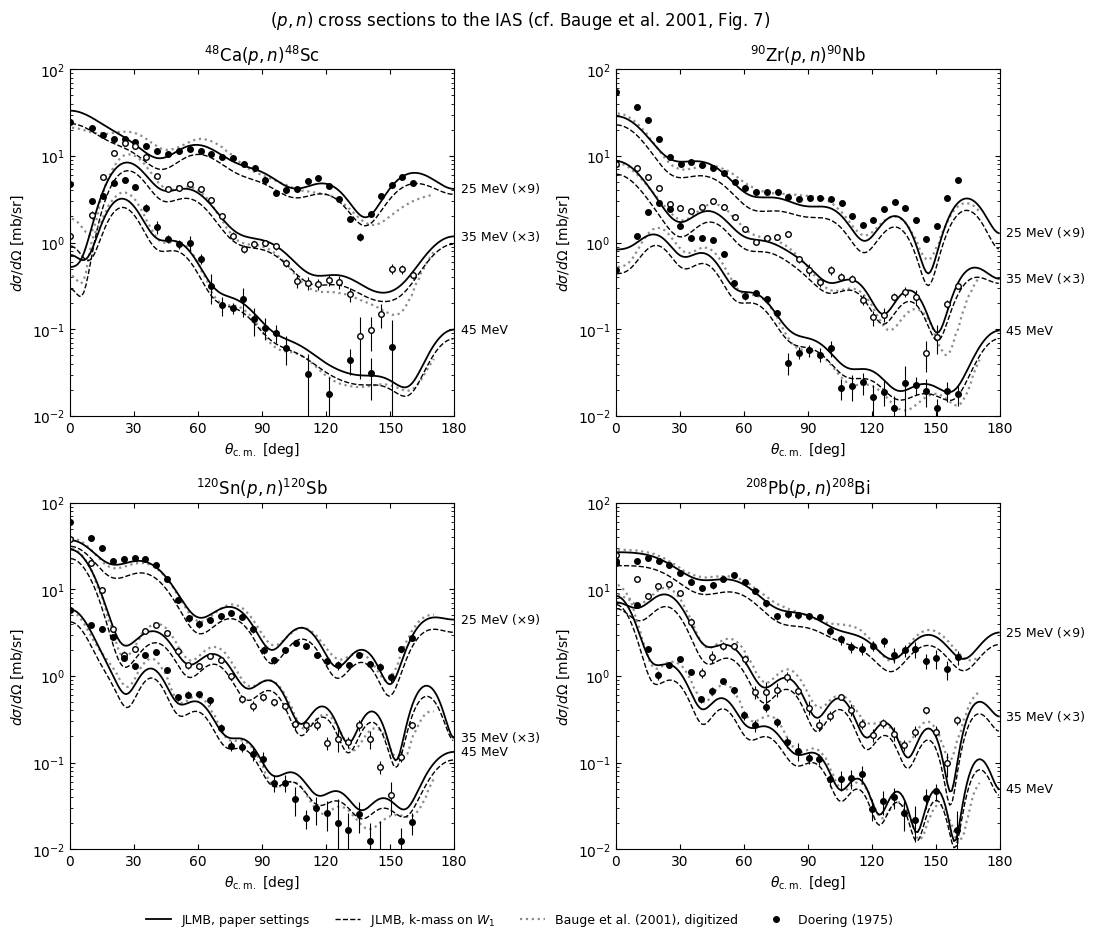

In [5]:
OFFSETS = {25.0: 9, 35.0: 3, 45.0: 1}


def nuclide(A, Z):
    return rf"$^{{{A}}}${periodictable.elements[Z].symbol}"


fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.42, bottom=0.1)
for ax, name in zip(axes.flat, TARGETS, strict=True):
    for c in (c for c in cases if c["name"] == name):
        offset = OFFSETS[c["E"]]
        ax.plot(fig7_theta, offset * c["bauge"], color="0.55", lw=1.6, ls=":")
        ax.plot(deg, offset * c["k_mass"], color="k", lw=1.0, ls="--")
        ax.plot(deg, offset * c["paper"], color="k", lw=1.3)
        ax.errorbar(
            c["theta"],
            offset * c["dsdo"],
            yerr=offset * c["dsdo_err"],
            fmt="o",
            ms=4,
            mfc="white" if c["E"] == 35.0 else "k",
            mec="k",
            ecolor="k",
            lw=0.8,
            capsize=0,
        )
        label = f"{c['E']:.0f} MeV" + (f" (×{offset})" if offset > 1 else "")
        ax.text(
            183.0,
            offset * c["paper"][-1],
            label,
            fontsize=9,
            va="center",
            clip_on=False,
        )
    A, Z = TARGETS[name]
    ax.set_title(f"{nuclide(A, Z)}$(p,n)${nuclide(A, Z + 1)}", fontsize=12)
    ax.set_yscale("log")
    ax.set_xlim(0, 180)
    ax.set_ylim(1e-2, 1e2)
    ax.set_xticks(range(0, 181, 30))
    ax.tick_params(direction="in", top=True, right=True, which="both")
    ax.set_xlabel(r"$\theta_{\rm c.m.}$ [deg]")
    ax.set_ylabel(r"$d\sigma/d\Omega$ [mb/sr]")

handles = [
    plt.Line2D([], [], color="k", lw=1.3),
    plt.Line2D([], [], color="k", lw=1.0, ls="--"),
    plt.Line2D([], [], color="0.55", lw=1.6, ls=":"),
    plt.Line2D([], [], ls="", marker="o", color="k", ms=4),
]
labels = [
    "JLMB, paper settings",
    r"JLMB, k-mass on $W_1$",
    "Bauge et al. (2001), digitized",
    "Doering (1975)",
]
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncols=4,
    frameon=False,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.01),
)
fig.suptitle(
    r"$(p,n)$ cross sections to the IAS (cf. Bauge et al. 2001, Fig. 7)", y=0.94
)
plt.show()

## Where this agrees with the paper, and where it does not

Below 90 degrees the paper settings reproduce the digitized curves of Fig. 7 to within about 15%,
most cases within 10%, at all three energies, and at 25 MeV they follow the paper over the whole angular range for
$^{90}$Zr, $^{120}$Sn and $^{208}$Pb. Keeping the k-mass factor on $W_1$ (dashed) lowers the cross
sections at all angles by roughly 30%, which is why we leave it off.

Beyond 90 degrees at 35 and 45 MeV, our cross sections lie 20-50% above the paper's for
$^{48}$Ca, $^{90}$Zr, $^{120}$Sn and for $^{208}$Pb at 45 MeV ($^{208}$Pb at 35 MeV lies about 20%
below). That difference is not explained by
any choice we could test: the energy at which $U_{QE}$ is evaluated (constant or local, with or
without a Coulomb correction) and the k-mass factor change all angles together, the neutron-channel
densities and the kinematics matter at the few-percent level, and the spin-orbit potential and the
absorption in the distorted waves either destroy the shape of the angular distributions or the
agreement with elastic scattering. The remaining candidates are the HFB-D1S densities of the paper
and details of its DWBA calculation that the paper does not report.